In [1]:
# Parameters (overridden during execution)
EPOCHS = 25
RUN_ID = 1
OUT_DIR = "/kaggle/working/outputs"

In [2]:
!pip install torchinfo
!pip install --quiet torchview graphviz

In [3]:
import os
import math
import time
import random
import multiprocessing
from datetime import timedelta
from pathlib import Path
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from glob import glob

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
from IPython.display import SVG, display

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

from timm.models.vision_transformer import VisionTransformer, PatchEmbed
from torchinfo import summary
from torchview import draw_graph

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
from torchvision import datasets, transforms
from torch.utils.data import random_split
from collections import Counter

In [6]:
import os
import shutil
from pathlib import Path

ZIP_PATH = "/content/archive (10).zip"
EXTRACT_PATH = "/content/lung_cancer"

# Remove previous extraction
if os.path.exists(EXTRACT_PATH):
    shutil.rmtree(EXTRACT_PATH)

# Create clean destination
os.makedirs(EXTRACT_PATH, exist_ok=True)

# Extract without interactive prompts
!unzip -oq "/content/archive (10).zip" -d /content/lung_cancer

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [7]:
import os
from pathlib import Path
from PIL import Image as PILImage

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

In [8]:
BASE_ROOT  = Path("/content/lung_cancer/Data")
TRAIN_ROOT = BASE_ROOT / "train"
VAL_ROOT   = BASE_ROOT / "valid"
TEST_ROOT  = BASE_ROOT / "test"

assert TRAIN_ROOT.exists(), "Train folder not found"
assert VAL_ROOT.exists(),   "Valid folder not found"
assert TEST_ROOT.exists(),  "Test folder not found"


In [9]:
from torch.utils.data import Dataset, DataLoader

# ============================================================
# PYTORCH LUNG CANCER DATASET - CORRECTED
# ============================================================

class LungDataset(Dataset):

    def __init__(self, root, transform=None):

        self.samples = []

        self.class_names = sorted([
            d for d in os.listdir(root)
            if (root / d).is_dir()
        ])

        self.class_to_idx = {
            c: i for i, c in enumerate(self.class_names)
        }

        self.transform = transform

        for cls in self.class_names:

            cls_dir = root / cls

            for img_name in os.listdir(cls_dir):

                if img_name.lower().endswith(
                    (".png", ".jpg", ".jpeg")
                ):

                    self.samples.append(
                        (
                            cls_dir / img_name,
                            self.class_to_idx[cls]
                        )
                    )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        path, label = self.samples[idx]

        # Explicit PIL Image reference prevents naming conflicts
        with PILImage.open(path) as image:
            img = image.convert("RGB")

        if self.transform is not None:
            img = self.transform(img)

        return img, label


print("LungDataset successfully defined!")
print("PIL Image.open available:", hasattr(PILImage, "open"))

LungDataset successfully defined!
PIL Image.open available: True


In [10]:
IMG_SIZE   = 224     # MUST match model input
BATCH_SIZE = 6

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),  # shape only
    transforms.ToTensor(),                    # required by PyTorch
])


In [11]:
# ============================================================
# DATASET INITIALIZATION
# ============================================================

train_ds = LungDataset(TRAIN_ROOT, transform)
val_ds   = LungDataset(VAL_ROOT, transform)
test_ds  = LungDataset(TEST_ROOT, transform)

CLASS_NAMES = train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)

print("Detected classes:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)

print("\nDataset sizes:")
print("Training:", len(train_ds))
print("Validation:", len(val_ds))
print("Testing:", len(test_ds))

Detected classes: ['adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib', 'large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa', 'normal', 'squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa']
Number of classes: 4

Dataset sizes:
Training: 613
Validation: 72
Testing: 315


In [12]:
CLASS_NAMES = train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)

print("Detected classes:")
for i, name in enumerate(CLASS_NAMES):
    print(f"{i}: {name}")

print(f"\nNumber of classes: {NUM_CLASSES}")


Detected classes:
0: adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib
1: large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa
2: normal
3: squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa

Number of classes: 4


In [13]:
# ============================================================
# DATALOADER INITIALIZATION
# ============================================================

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("All DataLoaders initialized successfully!")

All DataLoaders initialized successfully!


In [14]:
def show_random_images_per_class(
    dataset,
    class_names,
    n_per_class=5,
    seed=42
):
    random.seed(seed)
    torch.manual_seed(seed)

    # Extract labels
    labels = np.array([label for _, label in dataset])
    num_classes = len(class_names)

    fig, axes = plt.subplots(
        num_classes,
        n_per_class,
        figsize=(3 * n_per_class, 3 * num_classes),
        squeeze=False
    )

    for cls_idx in range(num_classes):
        cls_indices = np.where(labels == cls_idx)[0]
        selected = np.random.choice(
            cls_indices,
            size=min(n_per_class, len(cls_indices)),
            replace=False
        )

        for col, idx in enumerate(selected):
            img, _ = dataset[idx]
            img = img.permute(1, 2, 0).numpy()

            ax = axes[cls_idx, col]
            ax.imshow(img)
            ax.axis("off")

            if col == 0:
                ax.set_ylabel(
                    class_names[cls_idx],
                    fontsize=12,
                    rotation=90,
                    labelpad=10
                )

    plt.tight_layout()
    plt.show()


In [15]:
!pip install -q torchinfo
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from timm.models.vision_transformer import VisionTransformer

from torchinfo import summary

In [16]:
# ============================================================
# BASE MODEL + SINGLE ViT (56x56)
# No ViT-2
# No 2Max-Min Pooling
# No GELU
# ============================================================

class CNN_ViT_Model_SingleViT(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        # ----------------------------------------------------
        # 1. PRETRAINED MOBILENETV2 BACKBONE
        # ----------------------------------------------------

        pretrained_model = mobilenet_v2(
            weights=MobileNet_V2_Weights.DEFAULT
        )

        num_blocks1 = len(pretrained_model.features)

        # Freeze first half of MobileNetV2
        for param in pretrained_model.features[
            :num_blocks1 // 2
        ].parameters():
            param.requires_grad = False

        # Split MobileNetV2 into blocks
        self.mobilenet_feature_blocks_1 = nn.Sequential(
            *pretrained_model.features[:num_blocks1 - 3]
        )

        self.mobilenet_block_2nd_last = (
            pretrained_model.features[num_blocks1 - 3]
        )

        self.mobilenet_block_mid = (
            pretrained_model.features[num_blocks1 - 2]
        )

        self.mobilenet_block_last = (
            pretrained_model.features[num_blocks1 - 1]
        )

        # Output channels
        ch_2nd_last = self.mobilenet_block_2nd_last.out_channels  # 160
        ch_last = self.mobilenet_block_last.out_channels          # 1280
        ch_mid = self.mobilenet_block_mid.out_channels            # 320

        ch_concat = ch_last + ch_2nd_last                         # 1440

        # ----------------------------------------------------
        # 2. CNN-TO-ViT ADAPTER (56x56)
        # ----------------------------------------------------

        adapter_layers = [

            nn.Conv2d(
                ch_mid, 64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Upsample(
                size=(14, 14),
                mode="bilinear",
                align_corners=False
            ),

            nn.Conv2d(
                64, 32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Upsample(
                size=(28, 28),
                mode="bilinear",
                align_corners=False
            ),

            nn.Conv2d(
                32, 16,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),

            nn.Upsample(
                size=(56, 56),
                mode="bilinear",
                align_corners=False
            ),
        ]

        self.cnn_to_vit_adapter = nn.Sequential(
            *adapter_layers
        )

        # ----------------------------------------------------
        # 3. SINGLE ViT (56x56)
        # ----------------------------------------------------

        self.vit_encoder = VisionTransformer(
            img_size=56,
            patch_size=8,
            in_chans=16,
            num_classes=0,
            embed_dim=48,
            depth=2,
            num_heads=4,
            mlp_ratio=2,
            qkv_bias=True,
            norm_layer=nn.LayerNorm,
        )

        self.vit_encoder.head = nn.Identity()

        # ----------------------------------------------------
        # 4. ENABLE OVERLAPPING PATCHES
        # ----------------------------------------------------

        old_proj = self.vit_encoder.patch_embed.proj

        self.vit_encoder.patch_embed.proj = nn.Conv2d(
            old_proj.in_channels,
            old_proj.out_channels,
            kernel_size=8,
            stride=4,
            bias=old_proj.bias is not None,
        )

        # Calculate number of patches
        img_h, img_w = self.vit_encoder.patch_embed.img_size

        dummy = torch.zeros(
            1,
            old_proj.in_channels,
            img_h,
            img_w
        )

        with torch.no_grad():
            _, _, h, w = self.vit_encoder.patch_embed.proj(
                dummy
            ).shape

        num_patches = h * w

        # Reset positional embeddings
        self.vit_encoder.pos_embed = nn.Parameter(
            torch.zeros(
                1,
                num_patches + 1,
                self.vit_encoder.embed_dim
            )
        )

        nn.init.trunc_normal_(
            self.vit_encoder.pos_embed,
            std=0.02
        )

        # ----------------------------------------------------
        # 5. CNN PARALLEL BRANCH
        # ----------------------------------------------------

        self.cnn_parallel_head = nn.Sequential(

            nn.Conv2d(
                ch_concat, 128,
                kernel_size=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                128, 128,
                kernel_size=3,
                padding=0
            ),

            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d(1),

            nn.Flatten()
        )

        # ----------------------------------------------------
        # 6. FINAL CLASSIFIER
        # ----------------------------------------------------

        self.classifier_head = nn.Linear(
            48 + 128,
            num_classes
        )

    # ========================================================
    # FORWARD PASS
    # ========================================================

    def forward(self, x):

        # ----------------------------------------------------
        # 1. MOBILENETV2 FEATURE EXTRACTION
        # ----------------------------------------------------

        features_1 = self.mobilenet_feature_blocks_1(x)

        features_2nd_last = self.mobilenet_block_2nd_last(
            features_1
        )

        features_mid = self.mobilenet_block_mid(
            features_2nd_last
        )

        features_last = self.mobilenet_block_last(
            features_mid
        )

        # ----------------------------------------------------
        # 2. CNN FEATURE CONCATENATION
        # ----------------------------------------------------

        concatenated_cnn_features = torch.cat(
            [
                features_last,
                features_2nd_last
            ],
            dim=1
        )

        # ----------------------------------------------------
        # 3. CNN-TO-ViT ADAPTER
        # ----------------------------------------------------

        vit_input = self.cnn_to_vit_adapter(
            features_mid
        )

        # Output: (B, 16, 56, 56)

        # ----------------------------------------------------
        # 4. SINGLE ViT
        # ----------------------------------------------------

        vit_features = self.vit_encoder(
            vit_input
        )

        # Output: (B, 48)

        # ----------------------------------------------------
        # 5. CNN PARALLEL BRANCH
        # ----------------------------------------------------

        cnn_features = self.cnn_parallel_head(
            concatenated_cnn_features
        )

        # Output: (B, 128)

        # ----------------------------------------------------
        # 6. CONCATENATION
        # ----------------------------------------------------

        combined = torch.cat(
            [
                vit_features,
                cnn_features
            ],
            dim=1
        )

        # Output: (B, 176)

        # ----------------------------------------------------
        # 7. CLASSIFICATION
        # ----------------------------------------------------

        return self.classifier_head(combined)

In [17]:
model = CNN_ViT_Model_SingleViT(
    num_classes=NUM_CLASSES
)

model = model.to(device)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 108MB/s]


In [18]:
summary(
    model,
    input_size=(1, 3, 224, 224),
    col_names=[
        "input_size",
        "output_size",
        "num_params",
        "trainable"
    ]
)

Layer (type:depth-idx)                             Input Shape               Output Shape              Param #                   Trainable
CNN_ViT_Model_SingleViT                            [1, 3, 224, 224]          [1, 4]                    --                        Partial
├─Sequential: 1-1                                  [1, 3, 224, 224]          [1, 160, 7, 7]            --                        Partial
│    └─Conv2dNormActivation: 2-1                   [1, 3, 224, 224]          [1, 32, 112, 112]         --                        False
│    │    └─Conv2d: 3-1                            [1, 3, 224, 224]          [1, 32, 112, 112]         (864)                     False
│    │    └─BatchNorm2d: 3-2                       [1, 32, 112, 112]         [1, 32, 112, 112]         (64)                      False
│    │    └─ReLU6: 3-3                             [1, 32, 112, 112]         [1, 32, 112, 112]         --                        --
│    └─InvertedResidual: 2-2                      

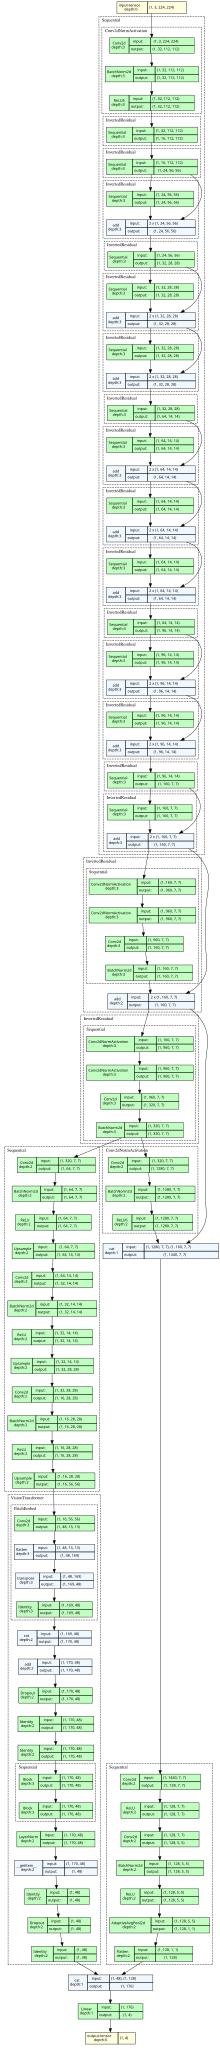

In [21]:
model.to(device)

# Dummy input (can adjust shape based on your model's expected input)
dummy_input = torch.randn(1, 3, 224, 224, device=device)

# Generate the graph — expand_nested=True if model has nested submodules
model_graph = draw_graph(
    model,
    input_data=dummy_input,
    expand_nested=True,
    graph_name="CNN_ViT_Model",
    save_graph=False  # We don't want to save, only display inline
)

# Render to SVG and display inline in the notebook
svg_output = model_graph.visual_graph.pipe(format='svg')
display(SVG(svg_output))

Architecture saved as: CNN_ViT_Model_Architecture.png


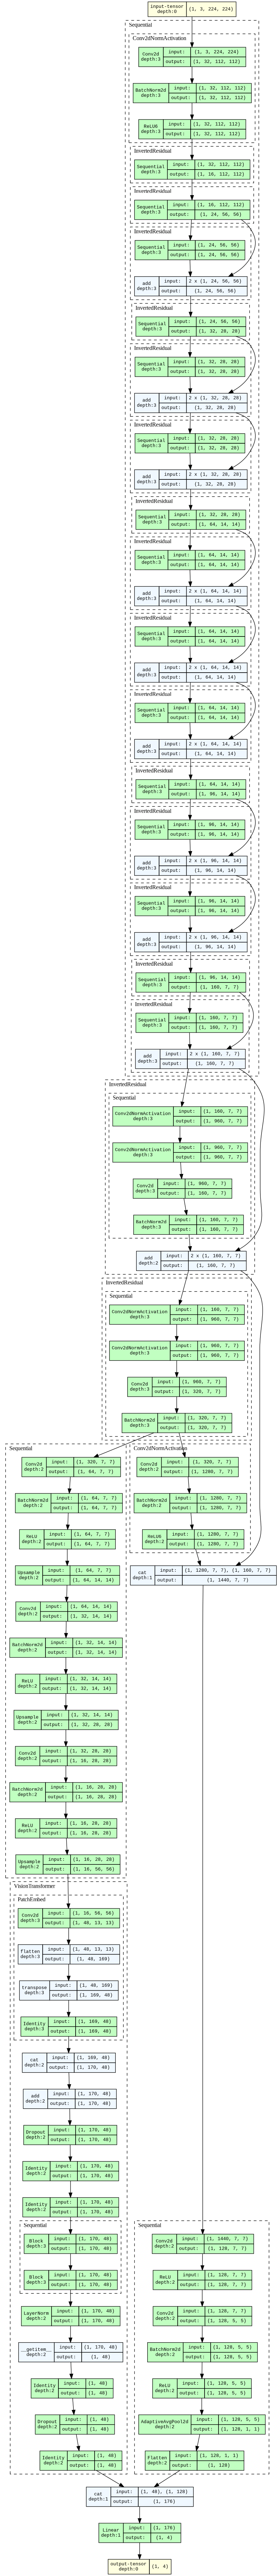

In [22]:
# ============================================================
# GENERATE AND SAVE MODEL ARCHITECTURE AS PNG
# ============================================================

import torch
from torchview import draw_graph
from IPython.display import Image, display

# Move model to device
model = model.to(device)
model.eval()

# Dummy input
dummy_input = torch.randn(
    1, 3, 224, 224,
    device=device
)

# Generate architecture graph
model_graph = draw_graph(
    model,
    input_data=dummy_input,
    expand_nested=True,
    graph_name="CNN_ViT_Model",
    save_graph=False
)

# Save as PNG
output_filename = "CNN_ViT_Model_Architecture.png"

model_graph.visual_graph.format = "png"

model_graph.visual_graph.render(
    filename="CNN_ViT_Model_Architecture",
    format="png",
    cleanup=True
)

print(f"Architecture saved as: {output_filename}")

# Display PNG inside notebook
display(Image(filename=output_filename))

In [23]:
def custom_metrics(y_pred, y_true, loss):
    y_pred_classes = torch.argmax(y_pred, dim=1)

    y_true_numpy = y_true.cpu().numpy()
    y_pred_classes_numpy = y_pred_classes.cpu().numpy()
    accuracy = accuracy_score(y_true_numpy, y_pred_classes_numpy)

    precision = precision_score(y_true_numpy, y_pred_classes_numpy, average='weighted', zero_division=0)
    recall = recall_score(y_true_numpy, y_pred_classes_numpy, average='weighted', zero_division=0)
    f1 = f1_score(y_true_numpy, y_pred_classes_numpy, average='weighted', zero_division=0)

    cm = confusion_matrix(y_true_numpy, y_pred_classes_numpy)

    tn = cm[0, 0]
    fp = cm[0, 1:].sum()
    fn = cm[1:, 0].sum()
    tp = cm[1:, 1:].sum()

    specificity = tn / (tn + fp) if (tn + fp) != 0 else 0.0
    sensitivity = tp / (tp + fn) if (tp + fn) != 0 else 0.0

    mcc = matthews_corrcoef(y_true_numpy, y_pred_classes_numpy)

    num_classes = y_pred.shape[1]
    auc_scores = []

    for class_idx in range(num_classes):
        class_y_true = (y_true_numpy == class_idx).astype(np.float32)
        class_y_pred = y_pred[:, class_idx].cpu().numpy()

        # Skip AUC if only one class is present
        if np.unique(class_y_true).size < 2:
            continue
        try:
            auc_score = roc_auc_score(class_y_true, class_y_pred)
            auc_scores.append(auc_score)
        except ValueError:
            continue

    auc_avg = np.mean(auc_scores) if auc_scores else 0.0

    metrics = {
        "loss": loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "specificity": specificity,
        "sensitivity": sensitivity,
        "mcc": mcc,
        "auc": auc_avg,
    }

    return metrics

In [24]:
# Hyperparameters
num_epochs       = EPOCHS
initial_lr       = 2e-4
decay_start_epoch = 10
decay_factor     = 0.97

# Criterion, optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=initial_lr)

# Scheduler policy: 1.0 until epoch 11, then 0.98^(epoch - 11)
lr_lambda = lambda epoch: 1.0 if epoch < decay_start_epoch else decay_factor ** (epoch - decay_start_epoch)
scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)

In [25]:
# Metrics initialization
metric_names = ["loss", "accuracy", "precision", "recall", "f1_score",
                "specificity", "sensitivity", "mcc", "auc"]
train_metrics_history = {metric: [] for metric in metric_names}
val_metrics_history = {metric: [] for metric in metric_names}

total_training_time = 0.0
total_validation_time = 0.0

# Training and validation loop
for epoch in range(num_epochs):
    start_time = time.time()

    # Training loop
    model.train()
    total_train_loss = 0.0
    all_train_predictions = []
    all_train_targets = []

    for batch_idx, (data, targets) in enumerate(tqdm(train_loader, desc=f"Training Epoch [{epoch + 1}/{num_epochs}]")):
        data = data.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()
        all_train_predictions.extend(outputs.detach().cpu().numpy())
        all_train_targets.extend(targets.detach().cpu().numpy())

    end_time = time.time()
    epoch_training_time = end_time - start_time
    total_training_time += epoch_training_time

    average_train_loss = total_train_loss / len(train_loader)
    all_train_predictions = np.array(all_train_predictions)
    all_train_targets = np.array(all_train_targets)

    train_metrics = custom_metrics(torch.tensor(all_train_predictions), torch.tensor(all_train_targets), average_train_loss)
    training_metrics_line = "Train Metrics - " + ", ".join([f"{k}: {v:.4f}" for k, v in train_metrics.items()])
    print(training_metrics_line)

    for metric in metric_names:
        train_metrics_history[metric].append(train_metrics[metric])

    # Validation loop
    model.eval()
    total_val_loss = 0.0
    all_val_predictions = []
    all_val_targets = []
    start_val_time = time.time()

    with torch.no_grad():
        for batch_idx, (data, targets) in enumerate(tqdm(val_loader, desc="Validating Model")):
            data = data.to(device)
            targets = targets.to(device)

            outputs = model(data)
            loss = criterion(outputs, targets)
            total_val_loss += loss.item()

            all_val_predictions.extend(outputs.detach().cpu().numpy())
            all_val_targets.extend(targets.detach().cpu().numpy())

    end_val_time = time.time()
    epoch_validation_time = end_val_time - start_val_time
    total_validation_time += epoch_validation_time

    average_val_loss = total_val_loss / len(val_loader)
    all_val_predictions = np.array(all_val_predictions)
    all_val_targets = np.array(all_val_targets)

    val_metrics = custom_metrics(torch.tensor(all_val_predictions), torch.tensor(all_val_targets), average_val_loss)
    validation_metrics_line = "Val Metrics - " + ", ".join([f"{k}: {v:.4f}" for k, v in val_metrics.items()])
    print(validation_metrics_line)

    for metric in metric_names:
        val_metrics_history[metric].append(val_metrics[metric])

    # Update LR via scheduler rather than manual mutliplication
    scheduler.step()

    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch}/{num_epochs} — Loss: {loss.item():.4f} — LR: {current_lr:.6f}")

print(f"Total Training Time: {str(timedelta(seconds=total_training_time))}")
print(f"Total Validation Time: {str(timedelta(seconds=total_validation_time))}")

avg_training_time_per_epoch = total_training_time / (epoch + 1)
avg_validation_time_per_epoch = total_validation_time / (epoch + 1)
print(f"Average Training Time per Epoch: {str(timedelta(seconds=avg_training_time_per_epoch))}")
print(f"Average Validation Time per Epoch: {str(timedelta(seconds=avg_validation_time_per_epoch))}")

Training Epoch [1/25]: 100%|██████████| 103/103 [00:07<00:00, 13.97it/s]


Train Metrics - loss: 0.9065, accuracy: 0.6069, precision: 0.6102, recall: 0.6069, f1_score: 0.5952, specificity: 0.6308, sensitivity: 0.7416, mcc: 0.4673, auc: 0.8260


Validating Model: 100%|██████████| 12/12 [00:00<00:00, 24.12it/s]


Val Metrics - loss: 0.6626, accuracy: 0.7083, precision: 0.7254, recall: 0.7083, f1_score: 0.7136, specificity: 0.6522, sensitivity: 0.8367, mcc: 0.6079, auc: 0.8918
Epoch 0/25 — Loss: 0.4626 — LR: 0.000200


Training Epoch [2/25]: 100%|██████████| 103/103 [00:05<00:00, 17.73it/s]


Train Metrics - loss: 0.4475, accuracy: 0.8352, precision: 0.8349, recall: 0.8352, f1_score: 0.8346, specificity: 0.8205, sensitivity: 0.8971, mcc: 0.7776, auc: 0.9600


... (90 outputs left out)

Training Epoch [25/25]: 100%|██████████| 103/103 [00:06<00:00, 15.46it/s]


Train Metrics - loss: 0.0553, accuracy: 0.9902, precision: 0.9903, recall: 0.9902, f1_score: 0.9902, specificity: 0.9846, sensitivity: 0.9976, mcc: 0.9868, auc: 0.9995


Validating Model: 100%|██████████| 12/12 [00:00<00:00, 22.50it/s]

Val Metrics - loss: 0.2626, accuracy: 0.8889, precision: 0.9091, recall: 0.8889, f1_score: 0.8916, specificity: 0.8696, sensitivity: 0.9796, mcc: 0.8560, auc: 0.9856
Epoch 24/25 — Loss: 0.0023 — LR: 0.000127
Total Training Time: 0:02:38.093423
Total Validation Time: 0:00:13.698896
Average Training Time per Epoch: 0:00:06.323737
Average Validation Time per Epoch: 0:00:00.547956


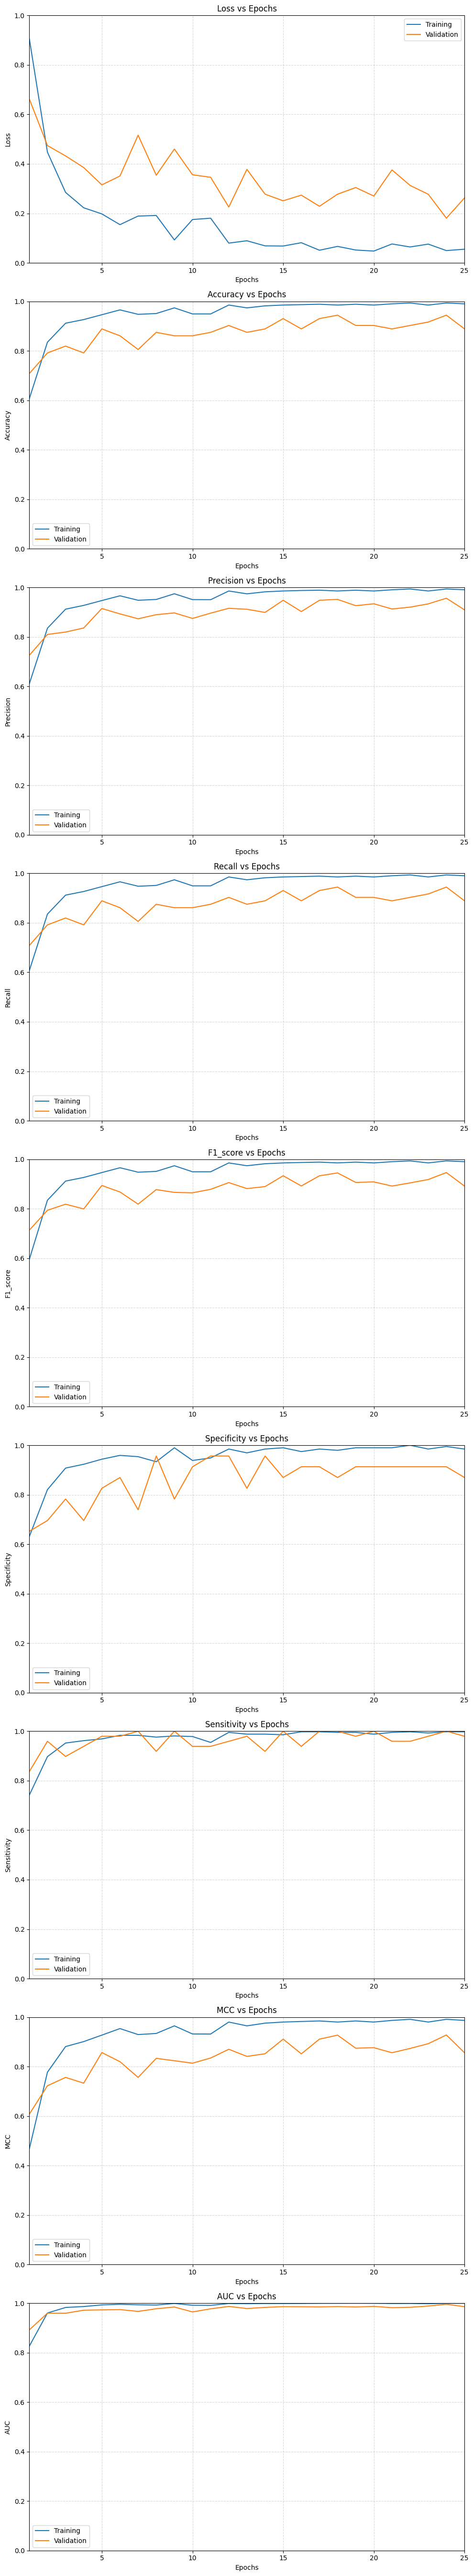

In [26]:
def plot_metrics(train_metrics_history, val_metrics_history, metric_names):
    num_metrics = len(metric_names)
    num_epochs = len(train_metrics_history[metric_names[0]])

    figure, axes = plt.subplots(num_metrics, figsize=(10, 6 * num_metrics))
    rng = range(1, num_epochs + 1)

    for ax, metric_name in zip(axes, metric_names):
        train_metric = train_metrics_history[metric_name]
        val_metric = val_metrics_history[metric_name]

        ax.plot(rng, train_metric, label="Training")
        ax.plot(rng, val_metric, label="Validation")
        ax.legend()
        ax.set_xlabel("Epochs")

        if metric_name in ("auc", "mcc"):
            ax.set_ylabel(metric_name.upper())
            ax.set_title(f"{metric_name.upper()} vs Epochs")
        else:
            ax.set_ylabel(metric_name.capitalize())
            ax.set_title(f"{metric_name.capitalize()} vs Epochs")

        max_metric = max(max(train_metric), max(val_metric))
        min_metric = min(min(train_metric), min(val_metric))
        y_max = math.ceil(max_metric)

        if min_metric > 0 or max_metric > 1:
            ax.set_ylim(0, y_max)
        else:
            ax.set_ylim(min_metric, y_max)

        ax.grid(True, linestyle='--', alpha=0.5)
        # Adjust xlim to avoid identical low and high limits.
        if num_epochs == 1:
            ax.set_xlim(0.5, 1.5)
        else:
            ax.set_xlim(1, num_epochs)

    plt.tight_layout()
    plt.show()

plot_metrics(train_metrics_history, val_metrics_history, metric_names)

In [27]:
# Testing loop
model.eval()
total_test_loss = 0.0
all_test_predictions = []
all_test_targets = []

with torch.no_grad():
    for batch_idx, (data, targets) in enumerate(tqdm(test_loader, desc="Testing Model")):
        data = data.to(device)
        targets = targets.to(device)

        outputs = model(data)
        loss = criterion(outputs, targets)
        total_test_loss += loss.item()

        all_test_predictions.extend(outputs.detach().cpu().numpy())
        all_test_targets.extend(targets.detach().cpu().numpy())

all_test_predictions = np.array(all_test_predictions)
all_test_targets = np.array(all_test_targets)

average_test_loss = total_test_loss / len(test_loader)
test_metrics = custom_metrics(torch.tensor(all_test_predictions), torch.tensor(all_test_targets), average_test_loss)
testing_metrics_line = "Test Metrics - " + ", ".join([f"{k}: {v:.4f}" for k, v in test_metrics.items()])
print(testing_metrics_line)

Testing Model: 100%|██████████| 53/53 [00:02<00:00, 20.90it/s]

Test Metrics - loss: 0.3546, accuracy: 0.8825, precision: 0.9012, recall: 0.8825, f1_score: 0.8837, specificity: 0.7667, sensitivity: 0.9795, mcc: 0.8458, auc: 0.9856


In [28]:
# Convert true labels and predictions to numpy
true_labels = np.array(all_test_targets)
predicted_labels = np.argmax(np.array(all_test_predictions), axis=1)

true_labels = true_labels.astype(int)
predicted_labels = predicted_labels.astype(int)

# Use dataset-derived class names (AUTO, SAFE)
classes = CLASS_NAMES

# Classification report
report = classification_report(
    true_labels,
    predicted_labels,
    target_names=classes,
    digits=4
)

# Accuracy
accuracy = accuracy_score(true_labels, predicted_labels)
num_errors = np.sum(true_labels != predicted_labels)

print(report)
print(
    f"There were {num_errors} errors in {len(predicted_labels)} tests "
    f"for an accuracy of {accuracy*100:.2f}%"
)


                                                  precision    recall  f1-score   support

      adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib     0.9583    0.7667    0.8519       120
   large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa     0.6944    0.9804    0.8130        51
                                          normal     1.0000    0.9815    0.9907        54
squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa     0.8830    0.9222    0.9022        90

                                        accuracy                         0.8825       315
                                       macro avg     0.8839    0.9127    0.8894       315
                                    weighted avg     0.9012    0.8825    0.8837       315

There were 37 errors in 315 tests for an accuracy of 88.25%
